# SheCare: Exploratory Data Analysis

**Course:** INT 234  
**Problem domain:** Menstrual health data analysis

SheCare uses recorded menstrual-cycle observations to understand cycle length,
cycle patterns, demographic associations, and menstrual and fertility measurements.
Exploratory Data Analysis (EDA) helps us understand the structure, quality,
distributions and relationships in the data before preprocessing or machine
learning. This notebook does not make medical claims and does not train a model.

The five research objectives are:
1. Understand menstrual-cycle length.
2. Investigate cycle patterns.
3. Explore demographic associations.
4. Explore menstrual and fertility relationships.
5. Assess whether cycle length is suitable for a future regression task.

The libraries used are **Pandas**, **NumPy**, **Matplotlib** and **Seaborn**.

In [4]:
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

project_dir = Path.cwd()
if (project_dir / "dataset" / "raw").exists():
    shecare_dir = project_dir
elif (project_dir.parent / "dataset" / "raw").exists():
    shecare_dir = project_dir.parent
else:
    shecare_dir = project_dir / "SheCare_INT234"
raw_file = shecare_dir / "dataset" / "raw" / "FedCycleData071012.csv"
figure_dir = shecare_dir / "visualizations"
result_dir = shecare_dir / "results"
figure_dir.mkdir(parents=True, exist_ok=True)
result_dir.mkdir(parents=True, exist_ok=True)
print("Project directory:", shecare_dir)

Project directory: /Users/abhijeet.ist/Developer/SheSync/SheCare_INT234


## 1. Project Introduction

This notebook follows a simple, reproducible EDA process. The original raw CSV
is never edited. Blank strings and whitespace-only cells are treated as missing
only in `working_df`, which is a separate copy used for analysis.

## 2. Load and Understand the Dataset

In [5]:
original_df = pd.read_csv(raw_file, keep_default_na=False)
working_df = original_df.copy()

# Treat blank strings as missing only in the working copy.
for column in working_df.columns:
    working_df[column] = working_df[column].replace(r"^\s*$", np.nan, regex=True)

print("Rows and columns:", original_df.shape)
print("Original raw file was loaded without changing it.")

Rows and columns: (1665, 80)
Original raw file was loaded without changing it.


In [6]:
original_df.head()

,ClientID,CycleNumber,Group,CycleWithPeakorNot,ReproductiveCategory,LengthofCycle,MeanCycleLength,EstimatedDayofOvulation,LengthofLutealPhase,FirstDayofHigh,TotalNumberofHighDays,TotalHighPostPeak,TotalNumberofPeakDays,TotalDaysofFertility,TotalFertilityFormula,LengthofMenses,MeanMensesLength,MensesScoreDayOne,MensesScoreDayTwo,MensesScoreDayThree,MensesScoreDayFour,MensesScoreDayFive,MensesScoreDaySix,MensesScoreDaySeven,MensesScoreDayEight,MensesScoreDayNine,MensesScoreDayTen,MensesScoreDay11,MensesScoreDay12,MensesScoreDay13,MensesScoreDay14,MensesScoreDay15,TotalMensesScore,MeanBleedingIntensity,NumberofDaysofIntercourse,IntercourseInFertileWindow,UnusualBleeding,PhasesBleeding,IntercourseDuringUnusBleed,Age,AgeM,Maristatus,MaristatusM,Yearsmarried,Wedding,Religion,ReligionM,Ethnicity,EthnicityM,Schoolyears,SchoolyearsM,OccupationM,IncomeM,Height,Weight,Reprocate,Numberpreg,Livingkids,Miscarriages,Abortions,Medvits,Medvitexplain,Gynosurgeries,LivingkidsM,Boys,Girls,MedvitsM,MedvitexplainM,Urosurgeries,Breastfeeding,Method,Prevmethod,Methoddate,Whychart,Nextpreg,NextpregM,Spousesame,SpousesameM,Timeattemptpreg,BMI
0,nfp8122,1,0,1,0,29,27.33,17,12,12,5,0,2,9,15,5,4.49,3,3,2,1,1,,,,,,,,,,,10,9.04,5,1,0,,,36,39,0,0,10,,0,0,0,0,8,8,3,5,63,120,0,3,3,0,0,0,,,,,,0,,,0,9,,,2,7,7,1,1,0,21.254724111867
1,nfp8122,2,0,1,0,27,,15,12,13,2,0,2,6,13,5,,3,3,2,1,1,,,,,,,,,,,10,,6,1,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2,nfp8122,3,0,1,0,29,,15,14,,1,0,2,5,13,5,,3,3,2,1,1,,,,,,,,,,,10,,5,1,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
3,nfp8122,4,0,1,0,27,,15,12,13,2,0,2,6,13,5,,3,3,3,2,1,,,,,,,,,,,12,,3,0,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
4,nfp8122,5,0,1,0,28,,16,12,12,4,0,2,8,14,5,,3,3,2,2,1,,,,,,,,,,,11,,5,1,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,


In [7]:
original_df.tail()

,ClientID,CycleNumber,Group,CycleWithPeakorNot,ReproductiveCategory,LengthofCycle,MeanCycleLength,EstimatedDayofOvulation,LengthofLutealPhase,FirstDayofHigh,TotalNumberofHighDays,TotalHighPostPeak,TotalNumberofPeakDays,TotalDaysofFertility,TotalFertilityFormula,LengthofMenses,MeanMensesLength,MensesScoreDayOne,MensesScoreDayTwo,MensesScoreDayThree,MensesScoreDayFour,MensesScoreDayFive,MensesScoreDaySix,MensesScoreDaySeven,MensesScoreDayEight,MensesScoreDayNine,MensesScoreDayTen,MensesScoreDay11,MensesScoreDay12,MensesScoreDay13,MensesScoreDay14,MensesScoreDay15,TotalMensesScore,MeanBleedingIntensity,NumberofDaysofIntercourse,IntercourseInFertileWindow,UnusualBleeding,PhasesBleeding,IntercourseDuringUnusBleed,Age,AgeM,Maristatus,MaristatusM,Yearsmarried,Wedding,Religion,ReligionM,Ethnicity,EthnicityM,Schoolyears,SchoolyearsM,OccupationM,IncomeM,Height,Weight,Reprocate,Numberpreg,Livingkids,Miscarriages,Abortions,Medvits,Medvitexplain,Gynosurgeries,LivingkidsM,Boys,Girls,MedvitsM,MedvitexplainM,Urosurgeries,Breastfeeding,Method,Prevmethod,Methoddate,Whychart,Nextpreg,NextpregM,Spousesame,SpousesameM,Timeattemptpreg,BMI
1660,nfp8334,7,1,1,0,29,,19,10,13,5,0,3,10,15,8,,2,3,3,2,2,1,1,1,,,,,,,,15,,8,0,1,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1661,nfp8334,8,1,1,0,28,,17,11,12,3,0,4,9,13,6,,3,3,2,1,1,1,,,,,,,,,,11,,11,1,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1662,nfp8334,9,1,1,0,28,,16,12,11,4,0,3,9,12,5,,3,2,2,1,1,,,,,,,,,,,9,,7,0,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1663,nfp8334,10,1,1,1,40,,27,13,13,13,0,1,,24,6,,2,3,3,2,1,1,,,,,,,,,,12,,3,0,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1664,nfp8334,11,1,1,2,24,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,


In [10]:
original_df.sample(5, random_state=42) #random state = 42 is used to ensure reproducibility of the sample

,ClientID,CycleNumber,Group,CycleWithPeakorNot,ReproductiveCategory,LengthofCycle,MeanCycleLength,EstimatedDayofOvulation,LengthofLutealPhase,FirstDayofHigh,TotalNumberofHighDays,TotalHighPostPeak,TotalNumberofPeakDays,TotalDaysofFertility,TotalFertilityFormula,LengthofMenses,MeanMensesLength,MensesScoreDayOne,MensesScoreDayTwo,MensesScoreDayThree,MensesScoreDayFour,MensesScoreDayFive,MensesScoreDaySix,MensesScoreDaySeven,MensesScoreDayEight,MensesScoreDayNine,MensesScoreDayTen,MensesScoreDay11,MensesScoreDay12,MensesScoreDay13,MensesScoreDay14,MensesScoreDay15,TotalMensesScore,MeanBleedingIntensity,NumberofDaysofIntercourse,IntercourseInFertileWindow,UnusualBleeding,PhasesBleeding,IntercourseDuringUnusBleed,Age,AgeM,Maristatus,MaristatusM,Yearsmarried,Wedding,Religion,ReligionM,Ethnicity,EthnicityM,Schoolyears,SchoolyearsM,OccupationM,IncomeM,Height,Weight,Reprocate,Numberpreg,Livingkids,Miscarriages,Abortions,Medvits,Medvitexplain,Gynosurgeries,LivingkidsM,Boys,Girls,MedvitsM,MedvitexplainM,Urosurgeries,Breastfeeding,Method,Prevmethod,Methoddate,Whychart,Nextpreg,NextpregM,Spousesame,SpousesameM,Timeattemptpreg,BMI
940,nfp8188,10,0,1,0,31,,19,12,15,4,0,2,8,14,4,,3,2,1,1,,,,,,,,,,,,7,,0,0,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
986,nfp8196,9,1,1,0,23,,11,12,,2,0,2,5,9,5,,3,3,2,1,1,,,,,,,,,,,10,,2,1,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
405,nfp8083,15,0,1,0,25,,15,10,12,3,0,2,7,14,4,,3,2,1,1,,,,,,,,,,,,7,,3,1,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
721,nfp8161,5,0,1,0,26,,14,12,,1,0,2,,12,5,,3,3,2,2,2,,,,,,,,,,,12,,0,0,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1610,nfp8324,2,1,1,0,23,,14,9,9,10,0,1,9,12,7,,1,2,3,3,2,1,1,,,,,,,,,13,,4,1,0,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,


In [14]:
print('Number of rows:', original_df.shape[0])
print('Number of columns:', original_df.shape[1]) 

Number of rows: 1665
Number of columns: 80


In [16]:
original_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1665 entries, 0 to 1664
Data columns (total 80 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   ClientID                    1665 non-null   object
 1   CycleNumber                 1665 non-null   int64 
 2   Group                       1665 non-null   int64 
 3   CycleWithPeakorNot          1665 non-null   int64 
 4   ReproductiveCategory        1665 non-null   int64 
 5   LengthofCycle               1665 non-null   int64 
 6   MeanCycleLength             1665 non-null   object
 7   EstimatedDayofOvulation     1665 non-null   object
 8   LengthofLutealPhase         1665 non-null   object
 9   FirstDayofHigh              1665 non-null   object
 10  TotalNumberofHighDays       1665 non-null   object
 11  TotalHighPostPeak           1665 non-null   object
 12  TotalNumberofPeakDays       1665 non-null   object
 13  TotalDaysofFertility        1665 non-null   obje

In [17]:
unique_values = working_df.nunique(dropna=True).sort_values()
unique_values.to_frame('unique_values')

,unique_values
MensesScoreDayTen,1
MensesScoreDay12,1
MensesScoreDay13,1
Timeattemptpreg,1
MensesScoreDay15,1
MensesScoreDay14,1
SpousesameM,2
MensesScoreDayNine,2
Group,2
CycleWithPeakorNot,2


In [18]:
print("CycleNumber summary:")
print(working_df["CycleNumber"].describe())

CycleNumber summary:
count    1665.000000
mean        8.040841
std         6.593686
min         1.000000
25%         3.000000
50%         7.000000
75%        11.000000
max        45.000000
Name: CycleNumber, dtype: float64


In [19]:
# Separate useful column groups using names and observed data types.

identifier_cols = ["ClientID"]

date_cols = []
for column in working_df.columns:
    if "date" in column.lower():
        date_cols.append(column)

numeric_cols = working_df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = []
for column in working_df.columns:
    if column not in identifier_cols and column not in numeric_cols and column not in date_cols:
        categorical_cols.append(column)

print("Numerical columns:", numeric_cols)
print("Categorical/text columns:", categorical_cols)
print("Identifier columns:", identifier_cols)
print("Date-related columns:", date_cols)

Numerical columns: ['CycleNumber', 'Group', 'CycleWithPeakorNot', 'ReproductiveCategory', 'LengthofCycle']
Categorical/text columns: ['MeanCycleLength', 'EstimatedDayofOvulation', 'LengthofLutealPhase', 'FirstDayofHigh', 'TotalNumberofHighDays', 'TotalHighPostPeak', 'TotalNumberofPeakDays', 'TotalDaysofFertility', 'TotalFertilityFormula', 'LengthofMenses', 'MeanMensesLength', 'MensesScoreDayOne', 'MensesScoreDayTwo', 'MensesScoreDayThree', 'MensesScoreDayFour', 'MensesScoreDayFive', 'MensesScoreDaySix', 'MensesScoreDaySeven', 'MensesScoreDayEight', 'MensesScoreDayNine', 'MensesScoreDayTen', 'MensesScoreDay11', 'MensesScoreDay12', 'MensesScoreDay13', 'MensesScoreDay14', 'MensesScoreDay15', 'TotalMensesScore', 'MeanBleedingIntensity', 'NumberofDaysofIntercourse', 'IntercourseInFertileWindow', 'UnusualBleeding', 'PhasesBleeding', 'IntercourseDuringUnusBleed', 'Age', 'AgeM', 'Maristatus', 'MaristatusM', 'Yearsmarried', 'Wedding', 'Religion', 'ReligionM', 'Ethnicity', 'EthnicityM', 'Schooly

**Dataset summary:** The dataset contains repeated cycle records for participants,
rather than one row per person. Several columns are stored as text because the
source uses blank strings for missing values. Numeric conversion is therefore
done explicitly for selected variables in the next sections.

## 3. Data Quality Analysis

In [22]:
missing_values = working_df.isna().sum().sort_values(ascending=False)
missing_percent = (missing_values / len(working_df) * 100).round(2)
missing_table = pd.DataFrame({
    "missing_values": missing_values,
    "missing_percent": missing_percent
})
missing_table.to_csv(result_dir / "missing_values_summary.csv")
missing_table.head(20)

,missing_values,missing_percent
MensesScoreDay13,1664,99.94
MensesScoreDay15,1664,99.94
MensesScoreDay14,1664,99.94
MensesScoreDay12,1664,99.94
MensesScoreDay11,1663,99.88
Urosurgeries,1662,99.82
MensesScoreDayTen,1659,99.64
Wedding,1655,99.40
Gynosurgeries,1639,98.44
MensesScoreDayNine,1639,98.44


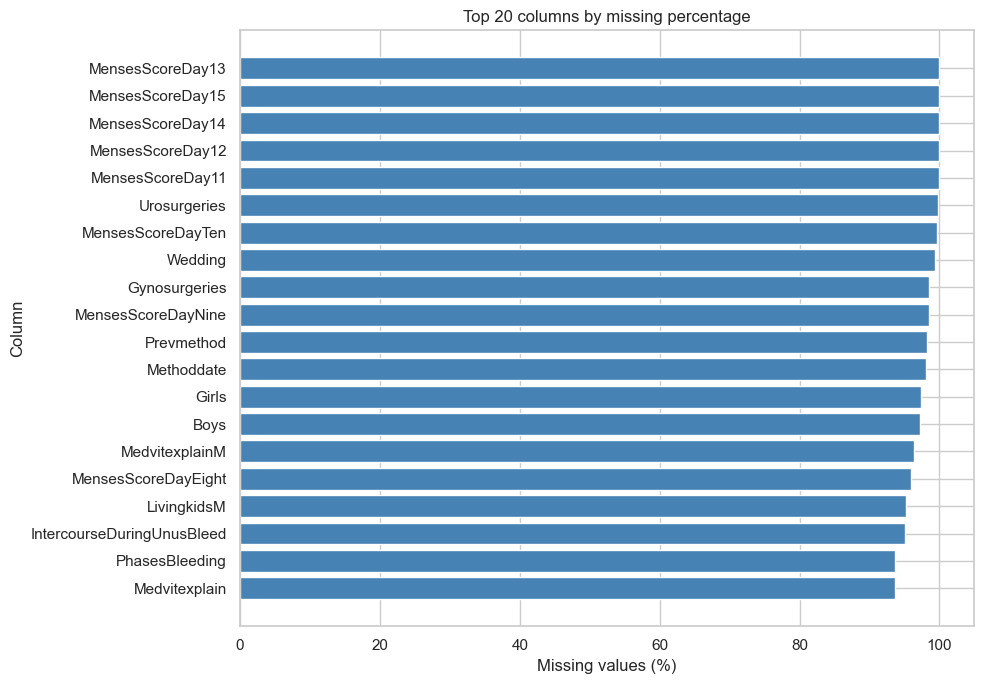

In [23]:
top_missing = missing_table.head(20).sort_values("missing_percent")
plt.figure(figsize=(10, 7))
plt.barh(top_missing.index, top_missing["missing_percent"], color="steelblue")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Top 20 columns by missing percentage")
plt.tight_layout()
plt.savefig(figure_dir / "missing_percentage_top20.png")
plt.show()

In [24]:

# Count exact duplicate rows
exact_duplicates = working_df.duplicated().sum()
repeated_keys = working_df.duplicated(
    subset=["ClientID", "CycleNumber"], keep=False
) # Find rows with repeated ClientID and CycleNumber
repeated_key_rows = working_df[repeated_keys]

# Print results
print("Exact duplicate rows:", exact_duplicates)
print("Repeated ClientID and CycleNumber rows:", len(repeated_key_rows))

# Display duplicate rows
if exact_duplicates > 0:
    display(working_df[working_df.duplicated(keep=False)].head())

# Display repeated records
display(repeated_key_rows[
    ["ClientID", "CycleNumber", "LengthofCycle"]
].head(20))


Exact duplicate rows: 12
Rows in repeated ClientID and CycleNumber groups: 32


,ClientID,CycleNumber,Group,CycleWithPeakorNot,ReproductiveCategory,LengthofCycle,MeanCycleLength,EstimatedDayofOvulation,LengthofLutealPhase,FirstDayofHigh,TotalNumberofHighDays,TotalHighPostPeak,TotalNumberofPeakDays,TotalDaysofFertility,TotalFertilityFormula,LengthofMenses,MeanMensesLength,MensesScoreDayOne,MensesScoreDayTwo,MensesScoreDayThree,MensesScoreDayFour,MensesScoreDayFive,MensesScoreDaySix,MensesScoreDaySeven,MensesScoreDayEight,MensesScoreDayNine,MensesScoreDayTen,MensesScoreDay11,MensesScoreDay12,MensesScoreDay13,MensesScoreDay14,MensesScoreDay15,TotalMensesScore,MeanBleedingIntensity,NumberofDaysofIntercourse,IntercourseInFertileWindow,UnusualBleeding,PhasesBleeding,IntercourseDuringUnusBleed,Age,AgeM,Maristatus,MaristatusM,Yearsmarried,Wedding,Religion,ReligionM,Ethnicity,EthnicityM,Schoolyears,SchoolyearsM,OccupationM,IncomeM,Height,Weight,Reprocate,Numberpreg,Livingkids,Miscarriages,Abortions,Medvits,Medvitexplain,Gynosurgeries,LivingkidsM,Boys,Girls,MedvitsM,MedvitexplainM,Urosurgeries,Breastfeeding,Method,Prevmethod,Methoddate,Whychart,Nextpreg,NextpregM,Spousesame,SpousesameM,Timeattemptpreg,BMI
45,nfp8114,1,0,1,0,28,31,14,14,NaN,1,0,2,5,12,4,4.5,3,2,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,7.5,0,0,0,NaN,NaN,39,36,0,0,4,NaN,0,0,0,0,9,9,0,3,68,185,0,2,2,0,0,1,multi-vitamin,NaN,NaN,NaN,NaN,1,"multi-vitamin, acid reducer",NaN,0,9,NaN,NaN,2,3,3,1,1,0,28.1260813148789
47,nfp8109,1,0,1,0,29,26.33,19,10,14,5,0,2,9,17,7,6.67,1,2,3,2,2,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12,12.33,2,1,0,NaN,NaN,29,32,0,0,8,NaN,4,0,0,5,8,8,0,5,66,180,0,2,2,0,0,1,Armour Thyroid 90 mg daily for hypothyroidism,NaN,NaN,NaN,NaN,0,NaN,NaN,0,9,NaN,NaN,2,3,3,1,1,0,29.0495867768595
48,nfp8109,2,0,1,0,23,NaN,14,9,9,5,0,2,9,12,7,NaN,1,3,3,2,2,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49,nfp8109,3,0,1,0,27,NaN,17,10,NaN,1,0,2,5,15,6,NaN,1,2,3,3,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12,NaN,2,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
52,nfp8107,3,0,1,0,25,NaN,16,9,10,6,0,2,10,14,6,NaN,1,2,2,2,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9,NaN,3,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,ClientID,CycleNumber,LengthofCycle
45,nfp8114,1,28
46,nfp8114,2,34
47,nfp8109,1,29
48,nfp8109,2,23
49,nfp8109,3,27
50,nfp8107,1,28
51,nfp8107,2,27
52,nfp8107,3,25
53,nfp8107,4,25
54,nfp8107,5,29


In [16]:
observed_unique = working_df.nunique(dropna=True)
very_few_observations = working_df.count().sort_values().head(15)
constant_columns = observed_unique[observed_unique <= 1]
high_missing_columns = missing_percent[missing_percent >= 80]
print("Constant columns:")
print(constant_columns)
print("\nColumns with the fewest observed values:")
print(very_few_observations)
print("\nColumns with at least 80% missing values:")
print(high_missing_columns)

Constant columns:
MensesScoreDayTen    1
MensesScoreDay12     1
MensesScoreDay13     1
MensesScoreDay14     1
MensesScoreDay15     1
Timeattemptpreg      1
dtype: int64

Columns with the fewest observed values:
MensesScoreDay15       1
MensesScoreDay13       1
MensesScoreDay12       1
MensesScoreDay14       1
MensesScoreDay11       2
Urosurgeries           3
MensesScoreDayTen      6
Wedding               10
MensesScoreDayNine    26
Gynosurgeries         26
Prevmethod            30
Methoddate            32
Girls                 43
Boys                  47
MedvitexplainM        60
dtype: int64

Columns with at least 80% missing values:
MensesScoreDay13              99.94
MensesScoreDay15              99.94
MensesScoreDay14              99.94
MensesScoreDay12              99.94
MensesScoreDay11              99.88
Urosurgeries                  99.82
MensesScoreDayTen             99.64
Wedding                       99.40
Gynosurgeries                 98.44
MensesScoreDayNine            98.4

In [17]:
categorical_check = {}
for column in working_df.select_dtypes(include="object").columns:
    values = working_df[column].dropna().astype(str)
    whitespace_values = values[values.str.strip() != values]
    categorical_check[column] = {
        "non_missing": len(values),
        "unique_values": values.nunique(),
        "leading_or_trailing_whitespace": len(whitespace_values)
    }
categorical_check = pd.DataFrame(categorical_check).T
categorical_check.sort_values("leading_or_trailing_whitespace", ascending=False).head(15)

,non_missing,unique_values,leading_or_trailing_whitespace
ClientID,1665,159,0
Medvitexplain,106,78,0
Abortions,139,3,0
Miscarriages,139,5,0
Livingkids,142,9,0
Numberpreg,142,11,0
Reprocate,142,7,0
Weight,134,56,0
Height,133,14,0
IncomeM,139,6,0


In [18]:
numeric_candidates = [
    "CycleNumber", "Group", "CycleWithPeakorNot", "ReproductiveCategory",
    "LengthofCycle", "LengthofMenses", "EstimatedDayofOvulation",
    "LengthofLutealPhase", "TotalDaysofFertility", "TotalMensesScore",
    "Age", "Height", "Weight", "BMI"
]
numeric_data = pd.DataFrame(index=working_df.index)
for column in numeric_candidates:
    if column in working_df.columns:
        numeric_data[column] = pd.to_numeric(working_df[column], errors="coerce")
numeric_data.describe().T

,count,mean,std,min,25%,50%,75%,max
CycleNumber,1665.0,8.040841,6.593686,1.000000,3.000000,7.000000,11.000000,45.00000
Group,1665.0,0.382583,0.486164,0.000000,0.000000,0.000000,1.000000,1.00000
CycleWithPeakorNot,1665.0,0.912312,0.282925,0.000000,1.000000,1.000000,1.000000,1.00000
ReproductiveCategory,1665.0,0.055255,0.479706,0.000000,0.000000,0.000000,0.000000,9.00000
LengthofCycle,1665.0,29.299099,3.887932,18.000000,27.000000,29.000000,31.000000,54.00000
LengthofMenses,1661.0,5.237207,1.255959,2.000000,4.000000,5.000000,6.000000,15.00000
EstimatedDayofOvulation,1515.0,15.963036,3.548488,6.000000,14.000000,15.000000,18.000000,29.00000
LengthofLutealPhase,1514.0,13.270806,2.671602,1.000000,12.000000,13.000000,14.000000,41.00000
TotalDaysofFertility,1634.0,7.995716,3.272571,0.000000,6.000000,7.000000,10.000000,27.00000
TotalMensesScore,1661.0,9.850090,2.786550,2.000000,8.000000,10.000000,11.000000,24.00000


**Data-quality interpretation:** Missing values are concentrated in optional
demographic, method and later menses-score fields. Repeated participant-cycle
keys and exact duplicate rows need investigation before preprocessing. Numeric
plausibility checks should use the meaning and units of each variable; this EDA
flags values for review but does not delete rows, fill missing values or remove
outliers.

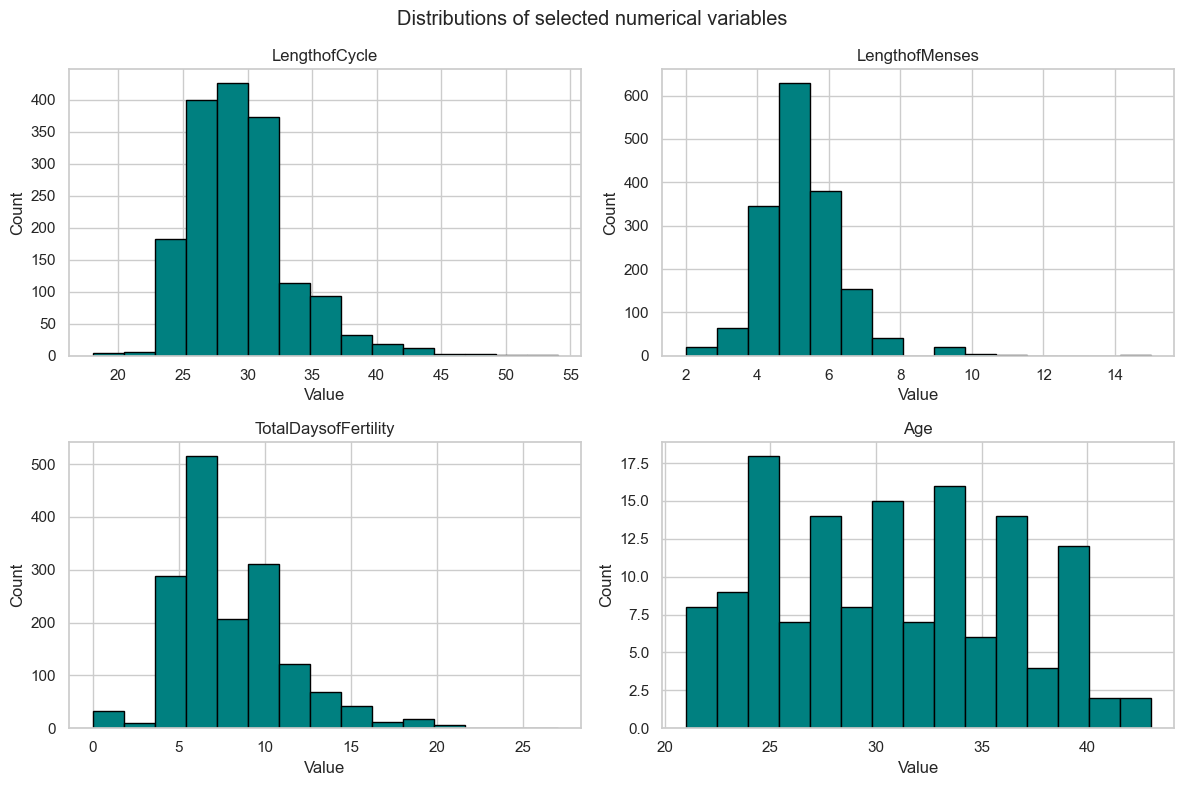

In [20]:
selected_histograms = ["LengthofCycle", "LengthofMenses", "TotalDaysofFertility", "Age"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, column in zip(axes.ravel(), selected_histograms):
    values = pd.to_numeric(working_df[column], errors="coerce").dropna()
    axis.hist(values, bins=15, color="teal", edgecolor="black")
    axis.set_title(column)
    axis.set_xlabel("Value")
    axis.set_ylabel("Count")
fig.suptitle("Distributions of selected numerical variables")
plt.tight_layout()
plt.savefig(figure_dir / "selected_numeric_histograms.png", dpi=150)
plt.show()

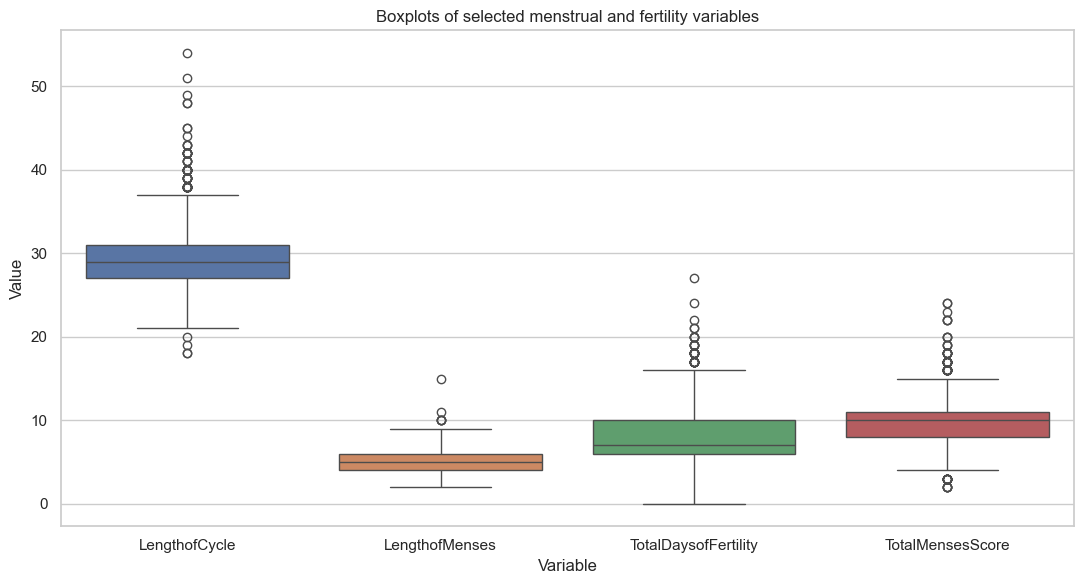

In [21]:
boxplot_columns = ["LengthofCycle", "LengthofMenses", "TotalDaysofFertility", "TotalMensesScore"]
boxplot_data = pd.DataFrame({
    column: pd.to_numeric(working_df[column], errors="coerce")
    for column in boxplot_columns
})
plt.figure(figsize=(11, 6))
sns.boxplot(data=boxplot_data)
plt.title("Boxplots of selected menstrual and fertility variables")
plt.xlabel("Variable")
plt.ylabel("Value")
plt.tight_layout()
plt.savefig(figure_dir / "selected_numeric_boxplots.png", dpi=150)
plt.show()

In [22]:
categorical_columns = ["CycleWithPeakorNot", "Group", "ReproductiveCategory", "Method"]
category_tables = []
for column in categorical_columns:
    counts = working_df[column].value_counts(dropna=False)
    percentages = (counts / len(working_df) * 100).round(2)
    table = pd.DataFrame({"column": column, "category": counts.index.astype(str),
                          "count": counts.values, "percent": percentages.values})
    category_tables.append(table)
category_summary = pd.concat(category_tables, ignore_index=True)
category_summary.to_csv(result_dir / "categorical_frequencies.csv", index=False)
display(category_summary)

,column,category,count,percent
0,CycleWithPeakorNot,1,1519,91.23
1,CycleWithPeakorNot,0,146,8.77
2,Group,0,1028,61.74
3,Group,1,637,38.26
4,ReproductiveCategory,0,1609,96.64
5,ReproductiveCategory,1,48,2.88
6,ReproductiveCategory,2,4,0.24
7,ReproductiveCategory,9,4,0.24
8,Method,nan,1523,91.47
9,Method,9,109,6.55


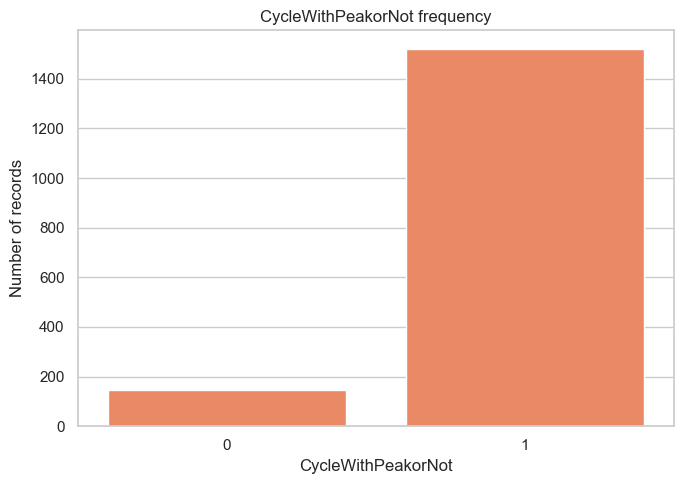

In [23]:
peak_counts = working_df["CycleWithPeakorNot"].value_counts().sort_index()
plt.figure(figsize=(7, 5))
sns.barplot(x=peak_counts.index.astype(str), y=peak_counts.values, color="coral")
plt.title("CycleWithPeakorNot frequency")
plt.xlabel("CycleWithPeakorNot")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(figure_dir / "cycle_peak_class_counts.png", dpi=150)
plt.show()

Categorical frequencies show the available classes and help identify imbalance. The values are descriptive and are not treated as medical categories without a data dictionary.

## 5. Participant and Cycle Analysis

In [24]:
cycles_per_participant = working_df.groupby("ClientID").size().sort_values(ascending=False)
cycle_count_summary = cycles_per_participant.describe()
print(cycle_count_summary)
cycle_count_summary.to_frame("cycles_per_participant").to_csv(result_dir / "cycles_per_participant_summary.csv")

count    159.000000
mean      10.471698
std        7.047588
min        1.000000
25%        5.000000
50%       12.000000
75%       13.000000
max       45.000000
dtype: float64


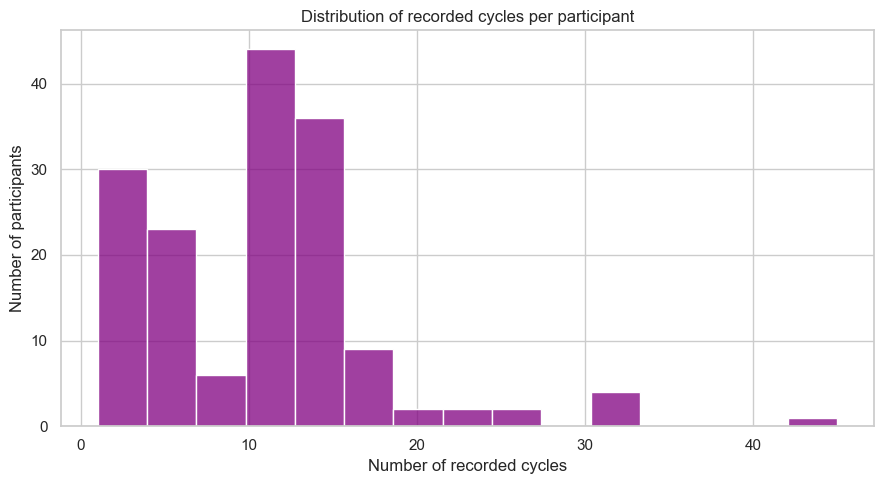

In [25]:
plt.figure(figsize=(9, 5))
sns.histplot(cycles_per_participant, bins=15, color="purple")
plt.title("Distribution of recorded cycles per participant")
plt.xlabel("Number of recorded cycles")
plt.ylabel("Number of participants")
plt.tight_layout()
plt.savefig(figure_dir / "cycles_per_participant.png", dpi=150)
plt.show()

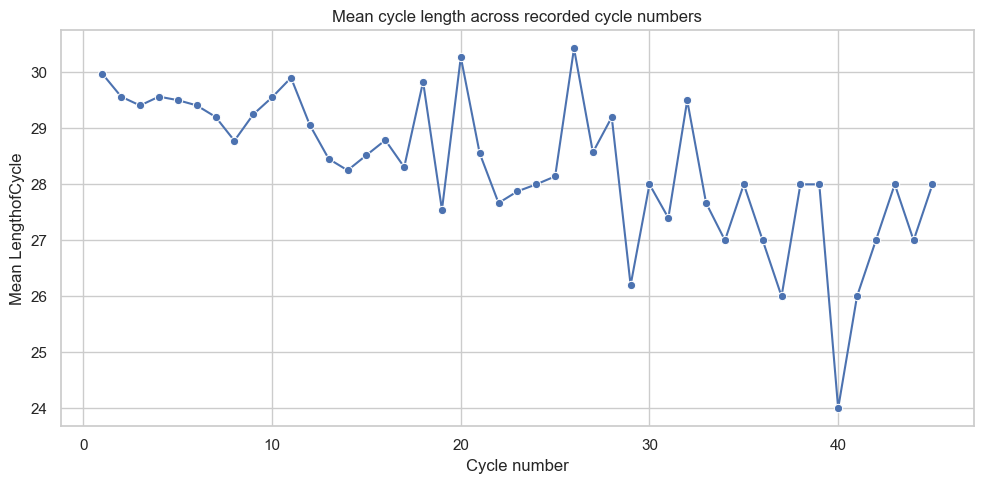

In [26]:
cycle_plot_data = working_df.copy()
cycle_plot_data["LengthofCycle_num"] = pd.to_numeric(cycle_plot_data["LengthofCycle"], errors="coerce")
cycle_by_number = cycle_plot_data.groupby("CycleNumber")["LengthofCycle_num"].agg(["count", "mean", "median"]).reset_index()
cycle_by_number.to_csv(result_dir / "cycle_length_by_cycle_number.csv", index=False)
plt.figure(figsize=(10, 5))
sns.lineplot(data=cycle_by_number, x="CycleNumber", y="mean", marker="o")
plt.title("Mean cycle length across recorded cycle numbers")
plt.xlabel("Cycle number")
plt.ylabel("Mean LengthofCycle")
plt.tight_layout()
plt.savefig(figure_dir / "cycle_length_by_cycle_number.png", dpi=150)
plt.show()

In [27]:
participant_variation = cycle_plot_data.groupby("ClientID")["LengthofCycle_num"].agg(
    ["count", "mean", "std", "min", "max"]
)
participant_variation.to_csv(result_dir / "participant_cycle_length_variation.csv")
participant_variation[participant_variation["count"] > 1].head()

,count,mean,std,min,max
ClientID,,,,,
nfp8020,16,25.875000,2.729469,18,31
nfp8024,12,28.750000,2.179449,26,34
nfp8026,6,27.666667,2.065591,25,30
nfp8030,16,26.750000,2.489980,23,30
nfp8031,12,27.166667,1.029857,25,29


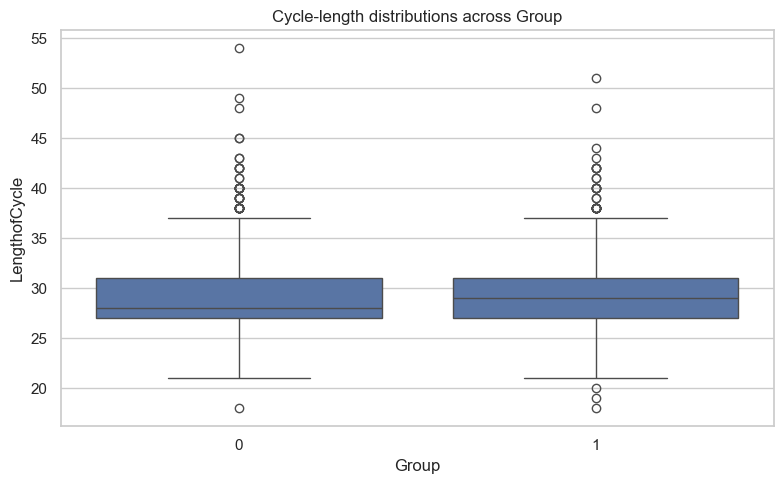

In [28]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=cycle_plot_data, x="Group", y="LengthofCycle_num")
plt.title("Cycle-length distributions across Group")
plt.xlabel("Group")
plt.ylabel("LengthofCycle")
plt.tight_layout()
plt.savefig(figure_dir / "cycle_length_by_group.png", dpi=150)
plt.show()

Participants with several cycles contribute multiple rows. These observations
can be correlated within a participant, so treating every row as an independent
person can overstate the amount of independent evidence.

## 6. Bivariate Analysis

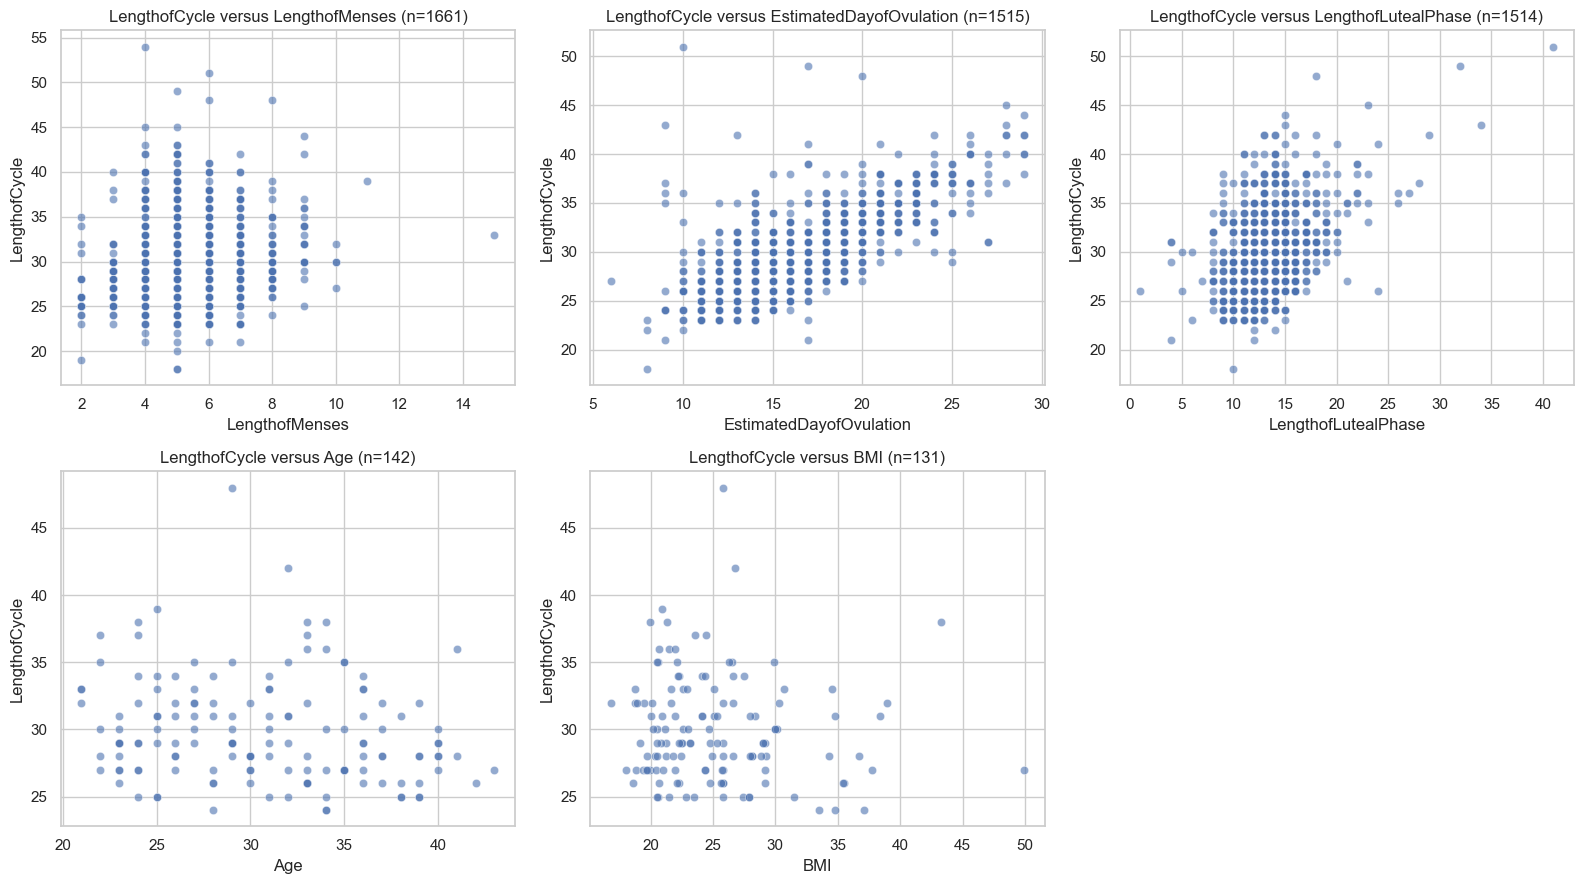

In [29]:
cycle_plot_data["LengthofMenses_num"] = pd.to_numeric(cycle_plot_data["LengthofMenses"], errors="coerce")
cycle_plot_data["EstimatedDayofOvulation_num"] = pd.to_numeric(cycle_plot_data["EstimatedDayofOvulation"], errors="coerce")
cycle_plot_data["LengthofLutealPhase_num"] = pd.to_numeric(cycle_plot_data["LengthofLutealPhase"], errors="coerce")
cycle_plot_data["Age_num"] = pd.to_numeric(cycle_plot_data["Age"], errors="coerce")
cycle_plot_data["BMI_num"] = pd.to_numeric(cycle_plot_data["BMI"], errors="coerce")

pairs = [
    ("LengthofMenses_num", "LengthofMenses", "LengthofCycle versus LengthofMenses"),
    ("EstimatedDayofOvulation_num", "EstimatedDayofOvulation", "LengthofCycle versus EstimatedDayofOvulation"),
    ("LengthofLutealPhase_num", "LengthofLutealPhase", "LengthofCycle versus LengthofLutealPhase"),
    ("Age_num", "Age", "LengthofCycle versus Age"),
    ("BMI_num", "BMI", "LengthofCycle versus BMI")
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for axis, (x_column, label, title) in zip(axes.ravel(), pairs):
    valid = cycle_plot_data[["LengthofCycle_num", x_column]].dropna()
    sns.scatterplot(data=valid, x=x_column, y="LengthofCycle_num", alpha=0.6, ax=axis)
    axis.set_title(title + " (n=" + str(len(valid)) + ")")
    axis.set_xlabel(label)
    axis.set_ylabel("LengthofCycle")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(figure_dir / "cycle_length_numeric_relationships.png", dpi=150)
plt.show()

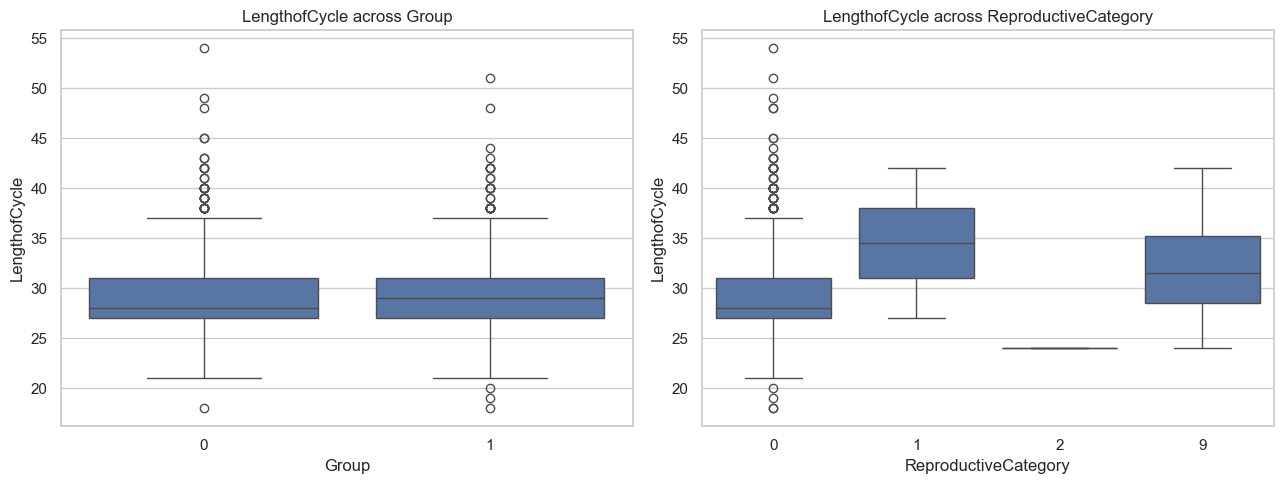

In [30]:
category_pairs = [("Group", "LengthofCycle across Group"),
                  ("ReproductiveCategory", "LengthofCycle across ReproductiveCategory")]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, (column, title) in zip(axes, category_pairs):
    sns.boxplot(data=cycle_plot_data, x=column, y="LengthofCycle_num", ax=axis)
    axis.set_title(title)
    axis.set_xlabel(column)
    axis.set_ylabel("LengthofCycle")
plt.tight_layout()
plt.savefig(figure_dir / "cycle_length_by_categories.png", dpi=150)
plt.show()

In [31]:
comparison_columns = ["LengthofCycle_num", "LengthofMenses_num",
                      "EstimatedDayofOvulation_num", "LengthofLutealPhase_num",
                      "TotalDaysofFertility", "TotalMensesScore"]
comparison_data = cycle_plot_data[comparison_columns].copy()
for column in comparison_columns:
    comparison_data[column] = pd.to_numeric(comparison_data[column], errors="coerce")
pair_counts = comparison_data.notna().sum()
pair_counts.to_frame("valid_observations").to_csv(result_dir / "bivariate_variable_counts.csv")
print("Valid observations available by variable:")
print(pair_counts)

Valid observations available by variable:
LengthofCycle_num              1665
LengthofMenses_num             1661
EstimatedDayofOvulation_num    1515
LengthofLutealPhase_num        1514
TotalDaysofFertility           1634
TotalMensesScore               1661
dtype: int64


Scatterplots are used for two numeric variables and boxplots for a numeric variable across categories. The title includes the valid row count where the scatterplot was created.

## 7. Correlation Analysis

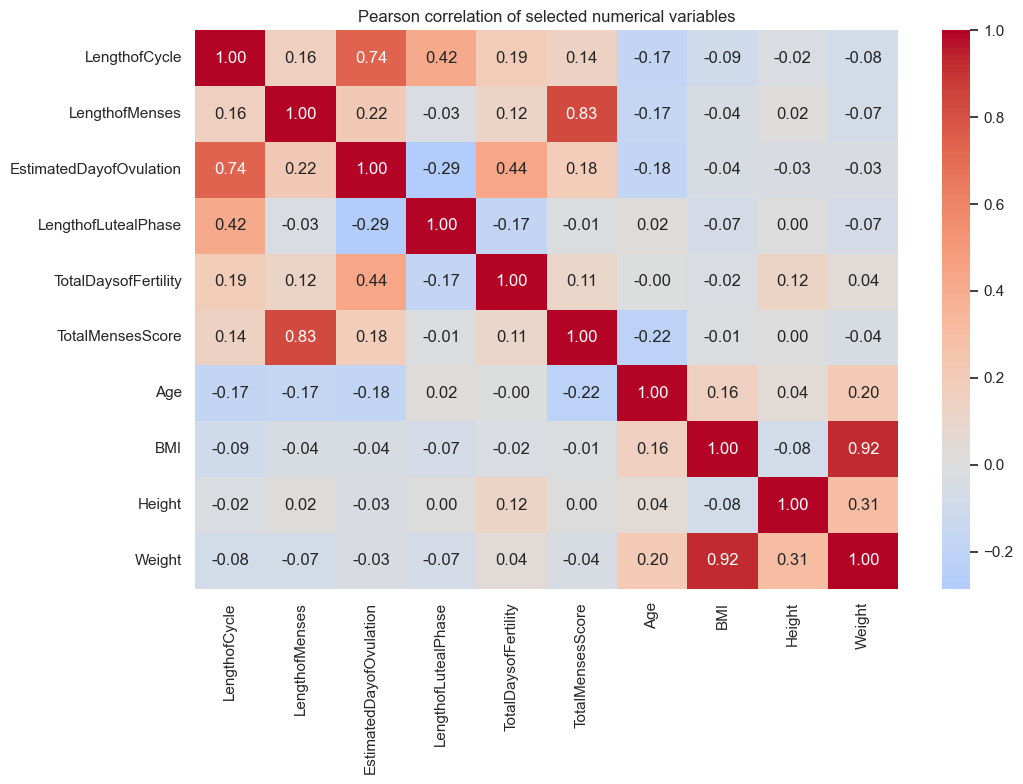

,correlation_with_LengthofCycle
LengthofCycle,1.000000
EstimatedDayofOvulation,0.736733
LengthofLutealPhase,0.415172
TotalDaysofFertility,0.194211
LengthofMenses,0.164946
TotalMensesScore,0.142562
Height,-0.020561
Weight,-0.081492
BMI,-0.093778
Age,-0.171342


In [32]:
correlation_columns = ["LengthofCycle", "LengthofMenses", "EstimatedDayofOvulation",
                       "LengthofLutealPhase", "TotalDaysofFertility",
                       "TotalMensesScore", "Age", "BMI", "Height", "Weight"]
correlation_data = pd.DataFrame()
for column in correlation_columns:
    correlation_data[column] = pd.to_numeric(working_df[column], errors="coerce")
correlation_matrix = correlation_data.corr(method="pearson")
correlation_matrix.to_csv(result_dir / "correlation_matrix.csv")
plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pearson correlation of selected numerical variables")
plt.tight_layout()
plt.savefig(figure_dir / "correlation_heatmap.png", dpi=150)
plt.show()
display(correlation_matrix["LengthofCycle"].sort_values(ascending=False).to_frame("correlation_with_LengthofCycle"))

Pearson correlation measures linear association and does not establish causation. Pairwise missing values mean different cells can use different numbers of observations.

## 8. Five Research Objectives

In [33]:
cycle_values = pd.to_numeric(working_df["LengthofCycle"], errors="coerce").dropna()
cycle_q1 = cycle_values.quantile(0.25)
cycle_q3 = cycle_values.quantile(0.75)
cycle_iqr = cycle_q3 - cycle_q1
cycle_lower = cycle_q1 - 1.5 * cycle_iqr
cycle_upper = cycle_q3 + 1.5 * cycle_iqr
cycle_outliers = ((cycle_values < cycle_lower) | (cycle_values > cycle_upper)).sum()
strongest_cycle_correlations = correlation_matrix["LengthofCycle"].drop("LengthofCycle").abs().sort_values(ascending=False)
print("Objective 1 - cycle length valid observations:", len(cycle_values))
print("Median:", cycle_values.median(), "Mean:", round(cycle_values.mean(), 2))
print("IQR boundaries:", cycle_lower, "to", cycle_upper)
print("Potential LengthofCycle outliers:", cycle_outliers)
print("\nObjective 2 - participants:", working_df["ClientID"].nunique(),
      "| median cycles per participant:", cycles_per_participant.median())
print("\nObjective 3 - valid Age and BMI observations:",
      cycle_plot_data[["Age_num", "BMI_num"]].notna().sum().to_dict())
print("\nObjective 4 - strongest absolute correlations with LengthofCycle:")
print(strongest_cycle_correlations.head(3))
print("\nObjective 5 - target missing values:", working_df["LengthofCycle"].isna().sum())

Objective 1 - cycle length valid observations: 1665
Median: 29.0 Mean: 29.3
IQR boundaries: 21.0 to 37.0
Potential LengthofCycle outliers: 73

Objective 2 - participants: 159 | median cycles per participant: 12.0

Objective 3 - valid Age and BMI observations: {'Age_num': 142, 'BMI_num': 131}

Objective 4 - strongest absolute correlations with LengthofCycle:
EstimatedDayofOvulation    0.736733
LengthofLutealPhase        0.415172
TotalDaysofFertility       0.194211
Name: LengthofCycle, dtype: float64

Objective 5 - target missing values: 0


### Objective 1: Understand menstrual-cycle length

- **Question:** What is the typical cycle length, how variable is it, and are potential outliers present?
- **Columns:** `LengthofCycle`.
- **Analysis:** Summary statistics, histogram, boxplot and IQR flags.
- **Actual observation:** The executed values are printed above and saved in `numeric_summary.csv`.
- **Interpretation:** The median and spread describe the observed records, while IQR flags identify records for review.
- **Limitation:** An IQR flag is not proof of an incorrect measurement.

### Objective 2: Investigate cycle patterns

- **Question:** Does cycle length differ across recorded cycle numbers and participants?
- **Columns:** `ClientID`, `CycleNumber`, `LengthofCycle`, `Group`.
- **Analysis:** Cycle-count distribution, cycle-number trend, participant variation and group boxplots.
- **Actual observation:** The cycle-number means and participant-level table are generated from the executed data.
- **Interpretation:** Repeated records allow within-participant variation to be inspected.
- **Limitation:** Rows from one participant are not statistically independent.

### Objective 3: Explore demographic associations

- **Question:** Are cycle length and available demographic measurements associated?
- **Columns:** `LengthofCycle`, `Age`, `BMI`, `Height`, `Weight`.
- **Analysis:** Scatterplots and correlation values where valid observations exist.
- **Actual observation:** Valid counts and correlations are printed above.
- **Interpretation:** Any visible pattern is descriptive and should not be read as causation.
- **Limitation:** Age and BMI have substantial missingness in this dataset.

### Objective 4: Explore menstrual and fertility relationships

- **Question:** How are cycle length, menses duration and fertility-related measurements related?
- **Columns:** `LengthofCycle`, `LengthofMenses`, `EstimatedDayofOvulation`, `LengthofLutealPhase`, `TotalDaysofFertility`, `TotalMensesScore`.
- **Analysis:** Scatterplots, valid-observation counts and correlation heatmap.
- **Actual observation:** Correlations and pairwise counts are produced above and saved to the results folder.
- **Interpretation:** Stronger correlations indicate linear association in the observed records only.
- **Limitation:** Missingness and repeated participants can affect the comparisons.

### Objective 5: Assess suitability for predicting cycle length

- **Question:** Is `LengthofCycle` a reasonable future regression target?
- **Columns:** `LengthofCycle` and candidate cycle, fertility and demographic predictors.
- **Analysis:** Target missingness, distributions, correlations, missingness and repeated-key checks.
- **Actual observation:** The target has no missing values in the source, but several possible predictors have many blanks.
- **Interpretation:** A future regression task is possible as a research exercise, but preprocessing and participant-aware validation are needed.
- **Limitation:** Variables recorded after or calculated from the cycle may cause leakage; a data dictionary and time-order review are required before modeling.

## 9. Outlier Analysis

In [34]:
outlier_rows = []
outlier_columns = ["LengthofCycle", "LengthofMenses", "EstimatedDayofOvulation",
                   "LengthofLutealPhase", "TotalDaysofFertility",
                   "TotalMensesScore", "Age", "BMI", "Height", "Weight"]
for column in outlier_columns:
    values = pd.to_numeric(working_df[column], errors="coerce").dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((values < lower) | (values > upper)).sum()
    outlier_rows.append({
        "column": column, "valid_count": len(values), "q1": q1, "q3": q3,
        "iqr": iqr, "lower_boundary": lower, "upper_boundary": upper,
        "potential_outliers": count
    })
outlier_summary = pd.DataFrame(outlier_rows)
outlier_summary.to_csv(result_dir / "iqr_outlier_summary.csv", index=False)
outlier_summary.round(2)

,column,valid_count,q1,q3,iqr,lower_boundary,upper_boundary,potential_outliers
0,LengthofCycle,1665,27.00,31.00,4.00,21.00,37.00,73
1,LengthofMenses,1661,4.00,6.00,2.00,1.00,9.00,6
2,EstimatedDayofOvulation,1515,14.00,18.00,4.00,8.00,24.00,44
3,LengthofLutealPhase,1514,12.00,14.00,2.00,9.00,17.00,98
4,TotalDaysofFertility,1634,6.00,10.00,4.00,0.00,16.00,38
5,TotalMensesScore,1661,8.00,11.00,3.00,3.50,15.50,72
6,Age,142,26.00,35.00,9.00,12.50,48.50,0
7,BMI,131,21.09,27.93,6.85,10.82,38.20,4
8,Height,133,63.00,67.00,4.00,57.00,73.00,0
9,Weight,134,127.25,170.00,42.75,63.12,234.12,5


IQR boundaries are screening rules. A flagged value may be a genuine observation,
a unit issue or a data-entry issue. No outliers are deleted or altered in this EDA;
they should be checked against the source documentation before preprocessing.

## 10. EDA Findings and Summary

In [35]:
top_missing_columns = missing_table.head(5).index.tolist()
highest_corr_column = strongest_cycle_correlations.index[0]
highest_corr_value = correlation_matrix.loc[highest_corr_column, "LengthofCycle"]
duplicate_key_count = int(working_df.duplicated(["ClientID", "CycleNumber"]).sum())
print("Key findings based on executed results:")
print("1. Dataset shape:", original_df.shape, "with", working_df["ClientID"].nunique(), "participants.")
print("2. LengthofCycle median and mean:", cycle_values.median(), "and", round(cycle_values.mean(), 2))
print("3. Potential LengthofCycle IQR outliers:", cycle_outliers)
print("4. Most missing columns:", top_missing_columns)
print("5. Exact duplicate rows:", exact_duplicates, "| repeated participant-cycle rows:", duplicate_key_count)
print("6. Strongest absolute selected correlation with LengthofCycle:", highest_corr_column, round(highest_corr_value, 2))
print("7. Target suitability: LengthofCycle is observed for", len(cycle_values), "records, but candidate predictors have missingness and leakage/repetition concerns.")

Key findings based on executed results:
1. Dataset shape: (1665, 80) with 159 participants.
2. LengthofCycle median and mean: 29.0 and 29.3
3. Potential LengthofCycle IQR outliers: 73
4. Most missing columns: ['MensesScoreDay13', 'MensesScoreDay15', 'MensesScoreDay14', 'MensesScoreDay12', 'MensesScoreDay11']
5. Exact duplicate rows: 12 | repeated participant-cycle rows: 16
6. Strongest absolute selected correlation with LengthofCycle: EstimatedDayofOvulation 0.74
7. Target suitability: LengthofCycle is observed for 1665 records, but candidate predictors have missingness and leakage/repetition concerns.


In [3]:
print("Hello World")

Hello World


### Main conclusions

- The data contains repeated cycle records from 159 participants, so participant-level repetition must be considered in later analysis.
- `LengthofCycle` is a complete target in the supplied file and its distribution, spread and potential IQR outliers are documented in the results.
- Menses, ovulation and fertility measurements can be compared descriptively, but missingness and source definitions limit interpretation.
- Age, BMI, height and weight are available only for a small subset, so demographic conclusions should remain cautious.
- Several columns have substantial missingness, especially optional method, demographic and later menses fields.
- Exact duplicates and repeated `ClientID`/`CycleNumber` combinations require source-level investigation rather than automatic deletion.
- Cycle-length prediction appears feasible as a future regression exercise, but predictors must be selected using time/order knowledge to avoid leakage.
- Recommended next steps are to create a documented preprocessing plan, confirm units and code meanings, decide how to handle repeated participants, and use participant-aware validation.